In [3]:
pip install opencv-python matplotlib 'numpy<2' scikit-image

Defaulting to user installation because normal site-packages is not writeable
INFO: pip is looking at multiple versions of opencv-python to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 20.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.7/13.7 MB 34.8 MB/s eta 0:00:00 0:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.2.6
    Uninstalling numpy-2.2.6:
      Successfully uninstalled numpy-2.2.6
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 4.13.0.92
    Uninstalling opencv-python-4.13.0.92:
      Successfully uninstalled opencv-python-4.13.0.92
Note: you may need to restart the kernel to use updated packages.


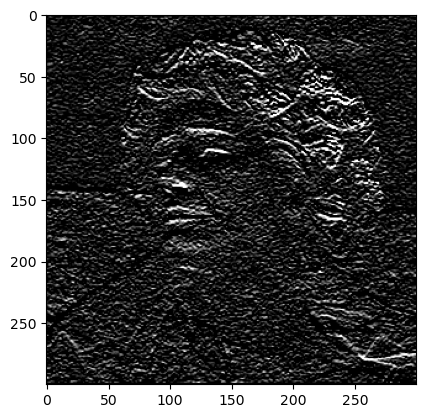

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('/Users/230363/Downloads/img.jpg',cv2.IMREAD_GRAYSCALE)
kernel = np.array([[1, 2, 1], [0, 0, 0], [-1,-2,-1]])
convolved_image = cv2.filter2D(image, -1, kernel)

plt.imshow(convolved_image, cmap='gray')
plt.show()

In [3]:
def box_filt(n):
    if n <= 0 or n % 2 == 0:
        raise ValueError("Window size must be a positive odd interger.")

    kernel = np.ones((n, n), dtype=np.float32) / (n * n)
    return kernel
    

In [4]:
def apply_filters(image_input, kernel, filt_size):
    
    pad_size = filt_size // 2
    
   
    image_padded = np.pad(image_input,
                          ((pad_size, pad_size), (pad_size, pad_size)),
                          mode='symmetric')
    
    rows, cols = image_input.shape
    output = np.zeros_like(image_input)
    
    for i in range(rows):
        for j in range(cols):
            
            patch = image_padded[i:i+filt_size, j:j+filt_size]
            output[i, j] = np.sum(patch * kernel)
    
    return output             

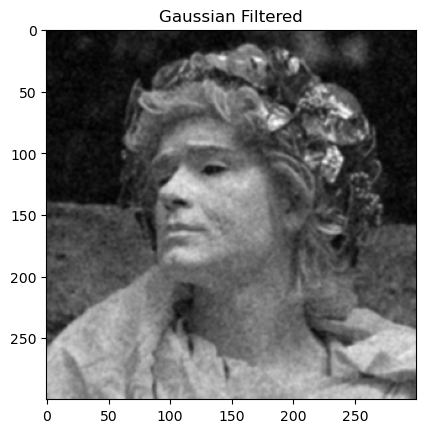

In [5]:
gaussian_filtered_image = cv2.GaussianBlur(image, (5, 5), 0)
plt.imshow(gaussian_filtered_image, cmap='gray')
plt.title('Gaussian Filtered')
plt.show()

In [6]:
def gauss_filt(n, sigma=1.0):

    if n <= 0 or n % 2 == 0:
        raise ValueError("Window size must be a positive odd integer.")

    ax = np.linspace(-(n - 1) / 2., (n - 1) / 2.,n)
    xx, yy = np.meshgrid(ax, ax)
    karnel = np.exp(-0.5 * (np.square(xx) + np.square(yy)) / np.square(sigma))
    kernel = kernel / np.sum(kernel)
    return kernel

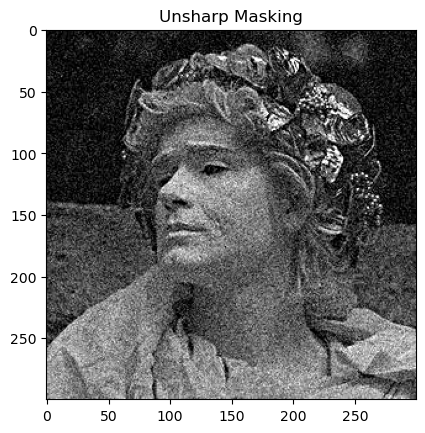

In [7]:
blurred = cv2.GaussianBlur(image, (9, 9), 10)
unsharp_image = cv2.addWeighted(image, 1.5,
blurred, -0.5, 0)
plt.imshow(unsharp_image, cmap='gray')
plt.title('Unsharp Masking')
plt.show()

In [11]:
import copy
import cv2
import numpy as np
from matplotlib import pyplot as plt

In [13]:
def box_filt(n):

    if n <= 0 or n % 2 == 0:
        raise ValueError("Window size must be a positive od integer.")
    kernel = np.ones((n, n), np.float32) / (n * n)
    return kernel

In [14]:
def apply_filters(image_input, box, filt_size):
    pad_size = int(np.ceil(filt_size/2))

    image_padded = np.pad(image_input,
pad_width=((pad_size,pad_size),(pad_size,pad_size)), mode='symmetric')
    image_box = copy.deepcopy(image_input)
    row, column = image_input.shape
    for i in range(row):
        for j in range(column):

            patch_curr = image_padded[i:i +filt_size, j:j + filt_size]
        results_box = box * patch_curr
        image_box[i,j] = np.sum(results_box)
    return image_box
    
filt_size = 5
k = 2

In [ ]:
image_input = cv2.imread('/Users/230363/Downloads/img.jpg',0).astype('float32')/255
box = box_filt(filt_size)
image_blur = apply_filters(image_input, box,filt_size)
image_diff = image_input - image_blur
image_sharp = image_input+k*image_diff
cv2.imshow('sharpen image', image_sharp)
cv2.waitKey(-1)